In [13]:
import numpy as np 
import pandas as pd 
import sys
import os
print(os.getenv("PYTHONPATH"))
import to_latex as latex
from pathlib import Path
export_dir = Path('./export') # Укажите ваш путь
export_file = export_dir / 'from_python.tex'
from to_latex import init_latex_export
init_latex_export() # создание латех файла
text = "Использован дополнительный модуль, написаный ИИ-моделью"
latex.save_text(text)

:/home/alex/Code/MIPT_phys_lab/Mechanics/modules_latex


## Измерения значения гармоник

In [14]:
# массы
mass = (0.4919+0.4915+0.1116, 0.4919+0.4915+0.1116+0.3437, 0.4946+0.4919+0.4915+0.1116+0.3437,
0.4946+0.4919+0.4915+0.1116+0.3437+0.4590+0.4874)
text = "Использованные для измерения массы:"
latex.save_text(text)
mass_dict = pd.DataFrame({'m0' : [round(mass[0],4)], 'm1' : [round(mass[1], 4)], 'm2' : [round(mass[2],4)], 'm3' : [round(mass[3], 4)]})
latex.save_table(mass_dict)
len(mass)


4

In [15]:
# частота осносной гармоники
# v1 = 1/(2*0.5)*((0.3437+0.1116)*9.81/(568.4*10**(-6)))**0.5
n_uneven = (1,3,5,7,9)
n_even = (2,4,6,8,10)

teor_even = {} 
teor_list = []
for idx, m in enumerate(mass):
    teor_list = []
    print(f'масса {m}')
    for i in n_even:
        v1 = round((i/(2*0.5))*(m*9.81/(568.4*10**(-6)))**0.5, 4)
        teor_list.append(v1)
        print(f"номер гармоники {i} частота = {v1}")
    teor_even[f'm{idx}'] = teor_list
teor_even = pd.DataFrame(teor_even)
text = "Теоретические частоты, расчитанные по формуле 9 лабораторной работы \n для четных гармоник:"
latex.save_text(text)
latex.save_table(teor_even)

teor_uneven = {} 
for idx, m in enumerate(mass):
    teor_list = []
    print(f'масса {m}')
    for i in n_uneven:
        v1 = round((i/(2*0.5))*(m*9.81/(568.4*10**(-6)))**0.5, 4)
        teor_list.append(v1)
        print(f"номер гармоники {i} частота = {v1}")
    teor_uneven[f'm{idx}'] = teor_list
teor_uneven = pd.DataFrame(teor_uneven)
text = "Теоретические частоты, расчитанные по формуле 9 лабораторной работы \n для нечетных гармоник:"
latex.save_text(text)
latex.save_table(teor_uneven)

масса 1.095
номер гармоники 2 частота = 274.9442
номер гармоники 4 частота = 549.8884
номер гармоники 6 частота = 824.8325
номер гармоники 8 частота = 1099.7767
номер гармоники 10 частота = 1374.7209
масса 1.4386999999999999
номер гармоники 2 частота = 315.1538
номер гармоники 4 частота = 630.3077
номер гармоники 6 частота = 945.4615
номер гармоники 8 частота = 1260.6153
номер гармоники 10 частота = 1575.7691
масса 1.9333
номер гармоники 2 частота = 365.3315
номер гармоники 4 частота = 730.6629
номер гармоники 6 частота = 1095.9944
номер гармоники 8 частота = 1461.3259
номер гармоники 10 частота = 1826.6574
масса 2.8797
номер гармоники 2 частота = 445.8729
номер гармоники 4 частота = 891.7458
номер гармоники 6 частота = 1337.6187
номер гармоники 8 частота = 1783.4916
номер гармоники 10 частота = 2229.3646
масса 1.095
номер гармоники 1 частота = 137.4721
номер гармоники 3 частота = 412.4163
номер гармоники 5 частота = 687.3604
номер гармоники 7 частота = 962.3046
номер гармоники 9 часто

In [16]:
# измерения гармоник для разных нагрузок

# четные гармоники
v_uneven = pd.DataFrame({'m0' : [137.0, 413.8, 692.4, 973.4, 1260.2], 
'm1' : [157.9, 475.5, 792.3, 1113.3, 1431.0],
'm2' : [182.0, 544.4, 914.2, 1275.3, 1643.1],
'm3' : [220.9, 666.3, 1107.1, 1550.0, 2000.5]})

# неченые гармоники
v_even = pd.DataFrame({'m0' : [278.8, 559.6, 825.5, 1101.4, 1366.6],
'm1' : [315.7, 634.4, 950.3, 1263.7, 1564.1],
'm2' : [368.0, 733.8, 1093, 1459, 1833.8],
'm3' : [444.7, 888.0, 1347, 1790.1, 2246.9]})

text = "Измеренные частоты для нечетных гармоник:"
latex.save_text(text)
latex.save_table(v_uneven)

text = "Измеренные частоты для четных гармоник:"
latex.save_text(text)
latex.save_table(v_even)

In [17]:
from scipy.optimize import curve_fit

#параметры установки:
L = 0.5
rho = 568.4*10**(-6)

def freq(n, k):
    return k*n

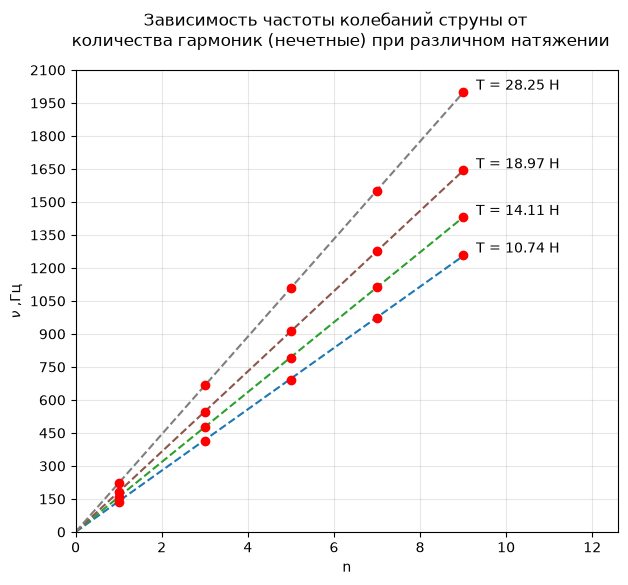

In [18]:
import matplotlib.pyplot as plt
from matplotlib import ticker

fig, ax = plt.subplots(figsize=(7,6))
ax.xaxis.set_major_locator(ticker.MultipleLocator(2))
ax.yaxis.set_major_locator(ticker.MultipleLocator(150))
colors = plt.cm.tab10(np.linspace(0, 1, 5))
count = 0
freqs = []

koeffs_uneven = {}
for i in v_uneven:
    k, var = curve_fit(f=freq, xdata=n_uneven, ydata=v_uneven[i])
    koeffs_uneven[i] = [k, var]
    ax.errorbar(x=n_uneven, y=v_uneven[i], yerr=[0.1]*len(v_uneven[i]), fmt='o', color = 'red')
    plt.grid(alpha = 0.3)
    ax.set_xlabel('n')
    ax.set_ylabel(r'$\nu \text{ ,Гц}$')
    ax.set_xlim(0, 12.6)
    ax.set_ylim(0, 2100)
    #ax.axline((0, 0), slope=k)
    ax.grid(True)
    # ax.plot(n_uneven, k*n_uneven, color = colors[count])
    x_extrap = np.linspace(0, max(n_uneven), 50)
    ax.plot(x_extrap, k*x_extrap, color = colors[count], linestyle='--')

    fig.suptitle('Зависимость частоты колебаний струны от \n количества гармоник (нечетные) при различном натяжении')
    ax.text(9 + 0.3, v_uneven[i][4]+ 10, f'T = {(mass[count]*9.81):.2f} Н')
    count += 1
latex.save_figure('uneven_plot', fig)
    #

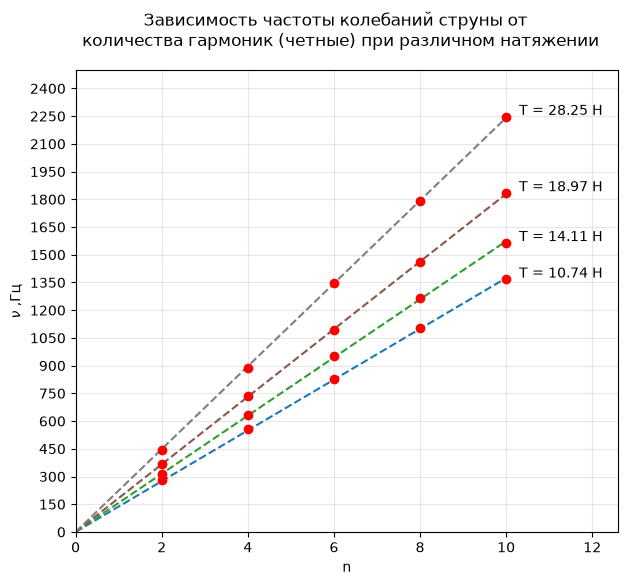

In [19]:
fig, ax = plt.subplots(figsize=(7,6))
ax.xaxis.set_major_locator(ticker.MultipleLocator(2))
ax.yaxis.set_major_locator(ticker.MultipleLocator(150))
colors = plt.cm.tab10(np.linspace(0, 1, 5))
count = 0

koeffs_even = {}
for i in v_even:
    k, var = curve_fit(f=freq, xdata=n_even, ydata=v_even[i])
    koeffs_even[i] = [k, var]
    ax.errorbar(n_even, v_even[i], yerr=[0.1]*len(v_even[i]), color = 'red', fmt='o')
    plt.grid(alpha = 0.3)
    ax.set_xlabel('n')
    ax.set_ylabel(r'$\nu \text{ ,Гц}$')
    ax.set_xlim(0, 12.6)
    ax.set_ylim(0, 2500)
    #ax.axline((0, 0), slope=k)
    x_extrap = np.linspace(0, max(n_even), 50)
    ax.plot(x_extrap, k*x_extrap, color = colors[count], linestyle='--')
    ax.grid(True)
    #ax.plot(n_even, k*n_even, color = colors[count])
    fig.suptitle('Зависимость частоты колебаний струны от \n количества гармоник (четные) при различном натяжении')
    ax.text(10 + 0.3, v_even[i][4]+ 10, f'T = {(mass[count]*9.81):.2f} Н')
    count += 1
latex.save_figure('even_plot', fig)
    #

In [20]:
koeffs_uneven[i][0]

array([221.87757576])

In [21]:
import sympy as sp 
from sympy import sqrt
k_sym, T_sym, n_sym, L_sym, rho_sym, u_sym = sp.symbols(r"k T n L \rho u")
koeff = (1/(2*L_sym)) * sqrt(T_sym/rho_sym)
f_koeff = sp.Eq(k_sym, koeff)
f_u = sp.Eq(u_sym, k_sym * 2*L_sym)
latex.save_text("Формулы для расчёта скорости волны из полученнного коэффициента наклона:")
latex.save_formulas([f_koeff, f_u])
vel_uneven = {' ' : [r'$u_{prac}$', r'$u_{teor}$', r'$u_{error, \%}$']}

# структура словаря такая: для каждой массы значение - лист. 1 - прак - 2 теор, 3- ошибка.
# для нечетных:
count = 0
for i in koeffs_uneven:
    vel_prac = koeffs_uneven[i][0][0] * 2 * L
    vel_uneven[i] = list([round(vel_prac, 2)])
    vel_teor = (9.81*mass[count]/rho)**0.5
    vel_uneven[i].append(round(vel_teor, 2))
    vel_error = abs(vel_teor - vel_prac)/vel_teor * 100
    vel_uneven[i].append(round(vel_error, 2))
    count += 1
text = "Формулы скорости волны (м/с), полученные из коэффициента наклона графика (МНК):"
latex.save_text(text)
text = "Для нечетных гармоник:"
latex.save_text(text)
vel_uneven = pd.DataFrame(vel_uneven)
latex.save_table(vel_uneven)

# для четных:ax.set_xlabel(r'$T$, Н')
ax.set_ylabel(r'$u^2, м/c')
ax.set_title("Зависимость квадрата скорости волны от нагрузки")
vel_even = {' ' : [r'$u_{prac}$', r'$u_{teor}$', r'$u_{error, \%}$']}
count = 0
for i in koeffs_even:
    vel_prac = koeffs_even[i][0][0] * 2 * L
    vel_even[i] = list([round(vel_prac, 2)])
    vel_teor = (9.81*mass[count]/rho)**0.5
    vel_even[i].append(round(vel_teor, 2))
    vel_error = abs(vel_teor - vel_prac)/vel_teor * 100
    vel_even[i].append(round(vel_error, 2))
    count += 1
vel_even = pd.DataFrame(vel_even)
text = "Для четных гармоник:"
latex.save_text(text)
latex.save_table(vel_even)
text = "где,"
latex.save_text(text)
text = r'$u_{teor}$ - скорость, расчитанная по формуле (2) лаб. работы'
latex.save_text(text)
text = r'$u_{prac}$ - скорость, расчитанная по коэффициенту наклона (2) лаб. работы'
latex.save_text(text)
text = r'$u_{error}$ - относительная ошибка практического измерения'
latex.save_text(text)

Eq(k, sqrt(T/\rho)/(2*L))

Eq(u, 2*L*k)

In [22]:
display(vel_even)
display(vel_uneven)

,,m0,m1,m2,m3
0,$u_{prac}$,137.39,157.37,182.91,224.15
1,$u_{teor}$,137.47,157.58,182.67,222.94
2,"$u_{error, \%}$",0.06,0.13,0.13,0.54


,,m0,m1,m2,m3
0,$u_{prac}$,139.37,158.90,182.43,221.88
1,$u_{teor}$,137.47,157.58,182.67,222.94
2,"$u_{error, \%}$",1.38,0.84,0.13,0.47


[0.00056914]
[0.00056494]
0.6087262491203242


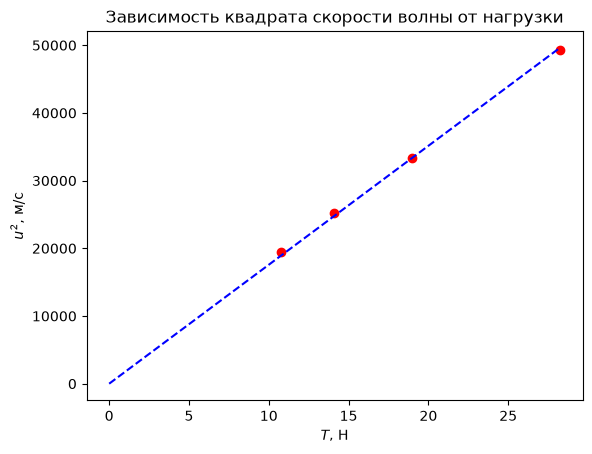

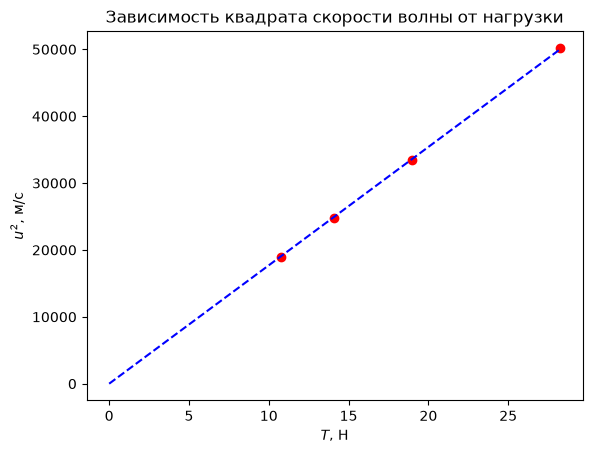

In [23]:
fig, ax = plt.subplots()
T = []
for i in mass:
    T.append(i*9.81)
T = np.array(T)
slope_uneven, var_un = curve_fit(freq, T, (vel_uneven.iloc[0, 1:])**2)
print(1/slope_uneven)
#for m, u in zip(mass, vel.iloc[0, 1:]):
ax.scatter(T, (vel_uneven.iloc[0, 1:])**2, color = 'red')
#ax.plot(T, T*slope_u, linestyle='--')
x_extrap = np.linspace(0, max(T), 50)
ax.plot(x_extrap, slope_uneven*x_extrap, linestyle='--', color='blue')
ax.set_xlabel(r'$T$, Н')
ax.set_ylabel(r'$u^2$, м/c')
ax.set_title("Зависимость квадрата скорости волны от нагрузки")
text = "Расчет погонной плотности:"
latex.save_text(text)
latex.save_figure('u2_uneven', fig)

fig, ax = plt.subplots()
slope_even, var_e = curve_fit(freq, T, (vel_even.iloc[0, 1:])**2)
print(1/slope_even)
#for m, u in zip(mass, vel.iloc[0, 1:]):
ax.scatter(T, (vel_even.iloc[0, 1:])**2, color = 'red')
#ax.plot(T, T*slope_u, linestyle='--')
x_extrap = np.linspace(0, max(T), 50)
ax.plot(x_extrap, slope_even*x_extrap, linestyle='--', color='blue')
ax.set_xlabel(r'$T$, Н')
ax.set_ylabel(r'$u^2$, м/c')
ax.set_title("Зависимость квадрата скорости волны от нагрузки")
latex.save_figure('u2_even', fig)

text = r"Расчитанный из коэффициента наклона $\rho$ :"
latex.save_text(text)
text = r'$\rho_1 = 569,14 \times 10^{-6}$'
latex.save_text(text)
text = r'$\rho_1 = 564,94 \times 10^{-6}$'
latex.save_text(text)
rho_error = abs(564.94-568.4)/568.4 * 100
print(rho_error)
text = r'$\rho_{error} = 0.6 \%$'
latex.save_text(text)




In [24]:
text = "Вывод: все экспериментально рассчитанные значения лежат в пределах 5% \n погрешности относительно теоретических. \n Измерения частот проведены достаточно точно."
latex.save_text(text)